In [1]:

import sys
import pandas as pd
import numpy as np
import matplotlib
import sklearn

print("Python:", sys.version.split()[0])
print("Pandas:", pd.__version__)
print("NumPy:", np.__version__)
print("Matplotlib:", matplotlib.__version__)
print("Scikit-learn:", sklearn.__version__)
print("Лабораторная №1 — Abalone. Всё работает!")


Python: 3.13.18
Pandas: 2.2.3
NumPy: 2.4.6
Matplotlib: 3.10.0
Scikit-learn: 1.6.1
Лабораторная №1 — Abalone. Всё работает!


In [2]:

import pandas as pd

# Названия столбцов
columns = [
    "Sex", "Length", "Diameter", "Height",
    "Whole_weight", "Shucked_weight",
    "Viscera_weight", "Shell_weight", "Rings"
]

# Загружаем данные из UCI
url = "https://archive.ics.uci.edu/ml/machine-learning-databases/abalone/abalone.data"

df = pd.read_csv(url, header=None, names=columns)

print("Количество строк:", df.shape[0])
print("Количество столбцов:", df.shape[1])

display(df.head(10))


Количество строк: 4177
Количество столбцов: 9


,Sex,Length,Diameter,Height,Whole_weight,Shucked_weight,Viscera_weight,Shell_weight,Rings
0,M,0.455,0.365,0.095,0.5140,0.2245,0.1010,0.150,15
1,M,0.350,0.265,0.090,0.2255,0.0995,0.0485,0.070,7
2,F,0.530,0.420,0.135,0.6770,0.2565,0.1415,0.210,9
3,M,0.440,0.365,0.125,0.5160,0.2155,0.1140,0.155,10
4,I,0.330,0.255,0.080,0.2050,0.0895,0.0395,0.055,7
5,I,0.425,0.300,0.095,0.3515,0.1410,0.0775,0.120,8
6,F,0.530,0.415,0.150,0.7775,0.2370,0.1415,0.330,20
7,F,0.545,0.425,0.125,0.7680,0.2940,0.1495,0.260,16
8,M,0.475,0.370,0.125,0.5095,0.2165,0.1125,0.165,9
9,F,0.550,0.440,0.150,0.8945,0.3145,0.1510,0.320,19


In [3]:

# Анализ качества данных Abalone

print("=== ИНФОРМАЦИЯ О ДАННЫХ ===")
df.info()

print("\n=== ПРОПУЩЕННЫЕ ЗНАЧЕНИЯ ===")
print(df.isnull().sum())

print("\n=== ПОВТОРЯЮЩИЕСЯ СТРОКИ ===")
print("Дубликатов:", df.duplicated().sum())

print("\n=== СТАТИСТИКА ЧИСЛОВЫХ ПРИЗНАКОВ ===")
display(df.describe().round(3))

print("\n=== РАСПРЕДЕЛЕНИЕ КАТЕГОРИИ SEX ===")
print(df["Sex"].value_counts())

print("\n=== СТАТИСТИКА ЦЕЛЕВОЙ ПЕРЕМЕННОЙ ===")
print("Минимум колец:", df["Rings"].min())
print("Максимум колец:", df["Rings"].max())
print("Среднее:", round(df["Rings"].mean(), 2))


=== ИНФОРМАЦИЯ О ДАННЫХ ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4177 entries, 0 to 4176
Data columns (total 9 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Sex             4177 non-null   object 
 1   Length          4177 non-null   float64
 2   Diameter        4177 non-null   float64
 3   Height          4177 non-null   float64
 4   Whole_weight    4177 non-null   float64
 5   Shucked_weight  4177 non-null   float64
 6   Viscera_weight  4177 non-null   float64
 7   Shell_weight    4177 non-null   float64
 8   Rings           4177 non-null   int64  
dtypes: float64(7), int64(1), object(1)
memory usage: 293.8+ KB

=== ПРОПУЩЕННЫЕ ЗНАЧЕНИЯ ===
Sex               0
Length            0
Diameter          0
Height            0
Whole_weight      0
Shucked_weight    0
Viscera_weight    0
Shell_weight      0
Rings             0
dtype: int64

=== ПОВТОРЯЮЩИЕСЯ СТРОКИ ===
Дубликатов: 0

=== СТАТИСТИКА ЧИСЛОВЫХ ПРИЗНАКОВ ===


,Length,Diameter,Height,Whole_weight,Shucked_weight,Viscera_weight,Shell_weight,Rings
count,4177.000,4177.000,4177.000,4177.000,4177.000,4177.000,4177.000,4177.000
mean,0.524,0.408,0.140,0.829,0.359,0.181,0.239,9.934
std,0.120,0.099,0.042,0.490,0.222,0.110,0.139,3.224
min,0.075,0.055,0.000,0.002,0.001,0.000,0.002,1.000
25%,0.450,0.350,0.115,0.442,0.186,0.094,0.130,8.000
50%,0.545,0.425,0.140,0.800,0.336,0.171,0.234,9.000
75%,0.615,0.480,0.165,1.153,0.502,0.253,0.329,11.000
max,0.815,0.650,1.130,2.826,1.488,0.760,1.005,29.000



=== РАСПРЕДЕЛЕНИЕ КАТЕГОРИИ SEX ===
Sex
M    1528
I    1342
F    1307
Name: count, dtype: int64

=== СТАТИСТИКА ЦЕЛЕВОЙ ПЕРЕМЕННОЙ ===
Минимум колец: 1
Максимум колец: 29
Среднее: 9.93


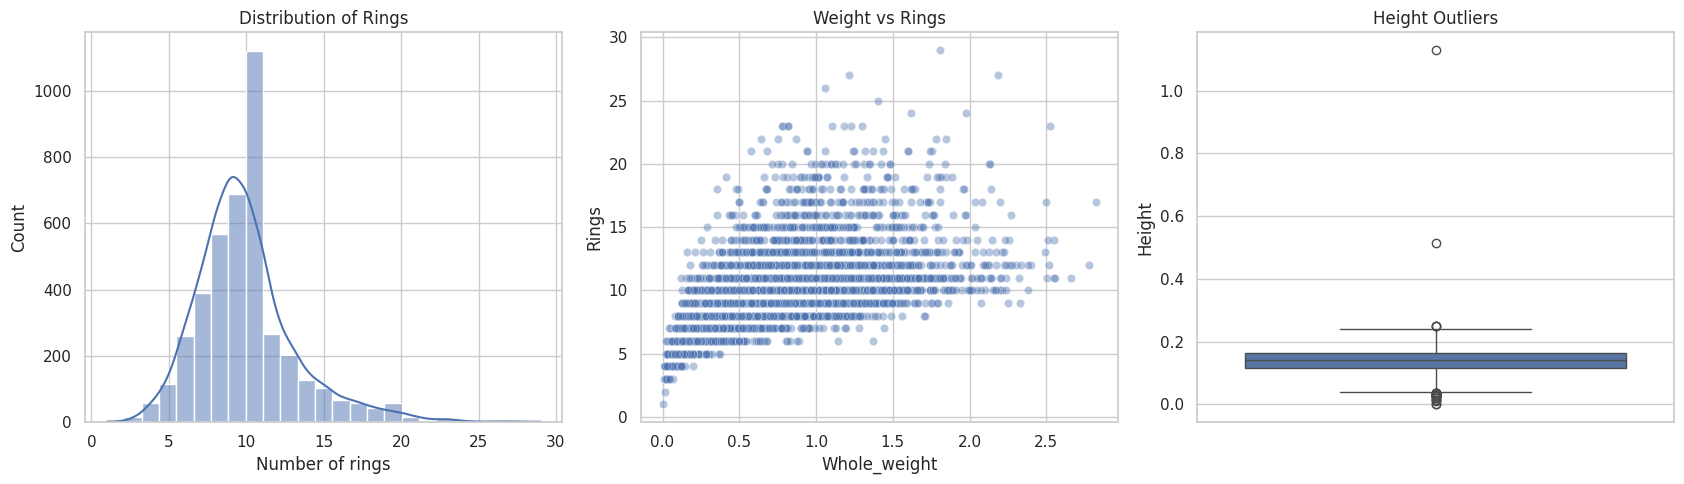

Графики сохранены: abalone_eda.png


In [4]:

import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

fig, axes = plt.subplots(1, 3, figsize=(17, 5))

# График 1. Распределение количества колец
sns.histplot(df["Rings"], bins=25, kde=True, ax=axes[0])
axes[0].set_title("Distribution of Rings")
axes[0].set_xlabel("Number of rings")

# График 2. Зависимость веса от количества колец
sns.scatterplot(
    data=df,
    x="Whole_weight",
    y="Rings",
    alpha=0.4,
    ax=axes[1]
)
axes[1].set_title("Weight vs Rings")

# График 3. Поиск выбросов по высоте
sns.boxplot(data=df, y="Height", ax=axes[2])
axes[2].set_title("Height Outliers")

plt.tight_layout()
plt.savefig("abalone_eda.png", dpi=150, bbox_inches="tight")
plt.show()

print("Графики сохранены: abalone_eda.png")


In [5]:

import json
from pathlib import Path

# Создаём папку для результатов
Path("artifacts").mkdir(exist_ok=True)

# Проверяем нулевую и необычно большую высоту
zero_height = df[df["Height"] == 0]
high_height = df[df["Height"] > 0.5]

print("Нулевая высота:", len(zero_height))
print("Высота больше 0.5:", len(high_height))

# Показываем подозрительные записи
anomalies = df[
    (df["Height"] == 0) | (df["Height"] > 0.5)
]

display(anomalies)

# Сохраняем таблицу аномалий
anomalies.to_csv(
    "artifacts/abalone_anomalies.csv",
    index=False
)

# Сохраняем основные показатели
stats = {
    "dataset": "Abalone",
    "rows": int(df.shape[0]),
    "columns": int(df.shape[1]),
    "missing_values": int(df.isnull().sum().sum()),
    "duplicates": int(df.duplicated().sum()),
    "zero_height": int(len(zero_height)),
    "height_above_0_5": int(len(high_height)),
    "rings_mean": float(df["Rings"].mean())
}

with open("artifacts/eda_summary.json", "w") as f:
    json.dump(stats, f, indent=4)

print("Результаты сохранены!")


Нулевая высота: 2
Высота больше 0.5: 2


,Sex,Length,Diameter,Height,Whole_weight,Shucked_weight,Viscera_weight,Shell_weight,Rings
1257,I,0.430,0.340,0.000,0.428,0.2065,0.0860,0.1150,8
1417,M,0.705,0.565,0.515,2.210,1.1075,0.4865,0.5120,10
2051,F,0.455,0.355,1.130,0.594,0.3320,0.1160,0.1335,8
3996,I,0.315,0.230,0.000,0.134,0.0575,0.0285,0.3505,6


Результаты сохранены!


In [6]:

import hashlib
import json
from pathlib import Path
from datetime import datetime, timezone
from urllib.request import urlopen

# Создаём папку для исходных данных
data_dir = Path("data/raw")
data_dir.mkdir(parents=True, exist_ok=True)

source_url = (
    "https://archive.ics.uci.edu/ml/"
    "machine-learning-databases/abalone/abalone.data"
)

# Скачиваем исходный файл без изменений
raw_data = urlopen(source_url, timeout=30).read()

file_path = data_dir / "abalone.data"
file_path.write_bytes(raw_data)

# Вычисляем контрольную сумму SHA-256
sha256 = hashlib.sha256(raw_data).hexdigest()

manifest = {
    "dataset": "UCI Abalone",
    "source": source_url,
    "filename": "abalone.data",
    "sha256": sha256,
    "size_bytes": len(raw_data),
    "rows": int(df.shape[0]),
    "columns": int(df.shape[1]),
    "downloaded_at_utc": datetime.now(
        timezone.utc
    ).isoformat()
}

Path("artifacts").mkdir(exist_ok=True)

with open(
    "artifacts/data_manifest.json",
    "w",
    encoding="utf-8"
) as f:
    json.dump(manifest, f, indent=4)

print("Исходные данные сохранены!")
print("SHA-256:", sha256)
print("Размер файла:", len(raw_data), "байт")
print("Манифест создан!")


Исходные данные сохранены!
SHA-256: de37cdcdcaaa50c309d514f248f7c2302a5f1f88c168905eba23fe2fbc78449f
Размер файла: 191873 байт
Манифест создан!


In [7]:

import hashlib
import json
from pathlib import Path

# Читаем сохранённый манифест
with open("artifacts/data_manifest.json", encoding="utf-8") as f:
    manifest = json.load(f)

# Повторно вычисляем контрольную сумму файла
file_bytes = Path("data/raw/abalone.data").read_bytes()
actual_hash = hashlib.sha256(file_bytes).hexdigest()

# Проверяем совпадение
assert actual_hash == manifest["sha256"], (
    "ОШИБКА: контрольная сумма не совпадает!"
)

print("ПРОВЕРКА ПРОЙДЕНА!")
print("Исходный файл не изменился.")
print("SHA-256:", actual_hash)


ПРОВЕРКА ПРОЙДЕНА!
Исходный файл не изменился.
SHA-256: de37cdcdcaaa50c309d514f248f7c2302a5f1f88c168905eba23fe2fbc78449f


In [8]:

import hashlib
from pathlib import Path

# Читаем настоящий файл
file_bytes = Path("data/raw/abalone.data").read_bytes()
actual_hash = hashlib.sha256(file_bytes).hexdigest()

# Специально создаём неправильную сумму
wrong_hash = "0" * 64

# Проверяем, обнаруживается ли ошибка
try:
    assert actual_hash == wrong_hash, (
        "Контрольная сумма не совпадает!"
    )
except AssertionError as error:
    print("НЕГАТИВНЫЙ КОНТРОЛЬ ПРОЙДЕН!")
    print("Программа обнаружила ошибку:", error)
else:
    raise RuntimeError(
        "ПРОВАЛ: неправильная контрольная сумма принята!"
    )


НЕГАТИВНЫЙ КОНТРОЛЬ ПРОЙДЕН!
Программа обнаружила ошибку: Контрольная сумма не совпадает!


In [9]:

from pathlib import Path
import shutil

# Создаём папку с графиками
Path("artifacts").mkdir(exist_ok=True)

# Переносим график в папку результатов
graph = Path("abalone_eda.png")
if graph.exists():
    shutil.copy2(graph, "artifacts/abalone_eda.png")

# Создаём архив с результатами
archive = shutil.make_archive(
    "Lab1_Abalone_results",
    "zip",
    root_dir=".",
    base_dir="artifacts"
)

print("Архив создан:", archive)
print("\nСодержимое:")
for file in sorted(Path("artifacts").rglob("*")):
    if file.is_file():
        print("-", file)


Архив создан: /content/Lab1_Abalone_results.zip

Содержимое:
- artifacts/abalone_anomalies.csv
- artifacts/abalone_eda.png
- artifacts/data_manifest.json
- artifacts/eda_summary.json
